# Phase 7: defacing head MRI

30 IXI T1 scans: 10 to choose margin and cut heights, 20 to test against quickshear and a fixed box. Faces are checked
on 8 renders per head with YuNet and Ultra-Light-Fast (a face counts only if both fire; thresholds from back-of-head
views of the originals). Utility: SynthStrip again after defacing, and a 3-class tissue segmentation.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import glob
import shutil
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

from fpdeid import paths
from fpdeid import deface

pd.set_option("display.width", 200)

phase_results = os.path.join(paths.RESULTS, "phase7")
os.makedirs(phase_results, exist_ok=True)
scans = sorted(glob.glob(os.path.join(paths.DATA, "ixi", "t1", "*.nii.gz")))
tune_scans = scans[:10]
test_scans = scans[10:]
print("scans:", len(scans), "| tune:", len(tune_scans), "| test:", len(test_scans))

scans: 30 | tune: 10 | test: 20


## 1. Load every scan once: brain mask (SynthStrip, GPU) and head mask

In [2]:
loaded = {}
strip_seconds = []
for path in scans:
    volume, affine, zooms = deface.load_ras(path)
    start = time.time()
    brain = deface.brain_mask(volume, affine)
    strip_seconds.append(time.time() - start)
    head = deface.head_mask(volume)
    loaded[path] = {"volume": volume, "affine": affine, "zooms": zooms, "brain": brain, "head": head}
print("SynthStrip seconds per scan:", round(float(np.mean(strip_seconds)), 1))

SynthStrip seconds per scan: 7.9


## 2. Calibrate the face detectors, then look for faces before defacing (8 views)
Threshold of each detector = just above its highest score on the back of the head (3 views per tune scan).

In [3]:
detectors = deface.FaceDetectors()
back_pictures = []
for path in tune_scans:
    head_iso = deface.isotropic(loaded[path]["head"], loaded[path]["zooms"])
    for yaw in [180, 150, -150]:
        back_pictures.append(deface.render(head_iso, yaw, 0))
yunet_threshold, ultralight_threshold = detectors.calibrate(back_pictures)
print("thresholds: YuNet", yunet_threshold, "| Ultra-Light", ultralight_threshold)

[ WARN:0@265.437] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


thresholds: YuNet 0.35 | Ultra-Light 0.8


In [4]:
BACK_VIEWS = [(180, 0), (150, 0), (-150, 0)]
before_rows = []
for path in scans:
    item = loaded[path]
    head_iso = deface.isotropic(item["head"], item["zooms"])
    views = deface.face_check(head_iso, detectors, deface.VIEWS + BACK_VIEWS)
    for view in views:
        view["scan"] = os.path.basename(path)
        before_rows.append(view)
before = pd.DataFrame(before_rows)
before["both"] = before["yunet"] & before["ultralight"]
before_by_view = before.groupby("view", sort=False)[["yunet", "ultralight", "both"]].mean().mul(100).round(1)
before_by_view.to_csv(os.path.join(phase_results, "faces_before_by_view.csv"))
before = before[~before["view"].isin(["yaw 180, pitch 0", "yaw 150, pitch 0", "yaw -150, pitch 0"])]
before_by_view

,yunet,ultralight,both
view,,,
"yaw 0, pitch 0",100.0,100.0,100.0
"yaw -30, pitch 0",100.0,96.7,96.7
"yaw 30, pitch 0",100.0,96.7,96.7
"yaw -60, pitch 0",86.7,10.0,10.0
"yaw 60, pitch 0",86.7,20.0,20.0
"yaw -90, pitch 0",36.7,6.7,3.3
"yaw 90, pitch 0",43.3,23.3,16.7
"yaw 0, pitch -20",100.0,83.3,83.3
"yaw 180, pitch 0",0.0,0.0,0.0


## 3. Choose the settings on the 10 tune scans
Margin around the brain, cut height above the frontal pole, and an optional chin limit. The chosen setting has the
fewest views where both detectors find a face, and then removes the least tissue.

In [6]:
def run_method(item, method, margin=10.0, above=15.0, below=None):
    start = time.time()
    if method == "fpdeid":
        defaced, removed = deface.deface_fpdeid(item["volume"], item["brain"], item["zooms"], margin, above, below)
    elif method == "quickshear":
        defaced, removed = deface.deface_quickshear(item["volume"], item["brain"])
    else:
        defaced, removed = deface.deface_box(item["volume"])
    seconds = time.time() - start
    return defaced, removed, seconds


settings_to_try = []
for margin in [10.0, 15.0, 20.0]:
    for above in [15.0, 25.0, 35.0]:
        for below in [None, 120.0]:
            settings_to_try.append((margin, above, below))

tuning_rows = []
for margin, above, below in settings_to_try:
    faces = 0
    removed_ml = []
    for path in tune_scans:
        item = loaded[path]
        defaced, removed, seconds = run_method(item, "fpdeid", margin, above, below)
        result = deface.evaluate(item["volume"], item["affine"], item["zooms"], item["brain"], item["head"],
                                 defaced, removed, detectors, check_utility=False)
        faces = faces + result["views with a face (both agree)"]
        removed_ml.append(result["removed tissue ml"])
    tuning_rows.append({"margin mm": margin, "cut above frontal pole mm": above,
                        "chin limit below frontal pole mm": "none" if below is None else below,
                        "views with a face (of 80)": faces, "removed tissue ml": round(float(np.mean(removed_ml)), 1)})
tuning = pd.DataFrame(tuning_rows)
tuning.to_csv(os.path.join(phase_results, "tuning.csv"), index=False)
tuning

,margin mm,cut above frontal pole mm,chin limit below frontal pole mm,views with a face (of 80),removed tissue ml
0,10.0,15.0,none,5,1181.8
1,10.0,15.0,120.0,3,952.9
2,10.0,25.0,none,8,1185.4
3,10.0,25.0,120.0,4,956.5
4,10.0,35.0,none,6,1189.5
5,10.0,35.0,120.0,5,960.6
6,15.0,15.0,none,7,1057.5
7,15.0,15.0,120.0,8,828.6
8,15.0,25.0,none,7,1057.6
9,15.0,25.0,120.0,8,828.6


In [7]:
best = tuning.sort_values(["views with a face (of 80)", "removed tissue ml"]).iloc[0]
MARGIN = float(best["margin mm"])
ABOVE = float(best["cut above frontal pole mm"])
BELOW = None if best["chin limit below frontal pole mm"] == "none" else float(best["chin limit below frontal pole mm"])
print("chosen: margin", MARGIN, "mm | cut", ABOVE, "mm above the frontal pole | chin limit", BELOW)

chosen: margin 10.0 mm | cut 15.0 mm above the frontal pole | chin limit 120.0


## 4. Test: the 20 test scans, three methods

In [8]:
test_rows = []
saved_examples = {}
for path in test_scans:
    item = loaded[path]
    for method in ["fpdeid", "quickshear", "box"]:
        defaced, removed, seconds = run_method(item, method, MARGIN, ABOVE, BELOW)
        result = deface.evaluate(item["volume"], item["affine"], item["zooms"], item["brain"], item["head"],
                                 defaced, removed, detectors, check_utility=True)
        result["scan"] = os.path.basename(path)
        result["method"] = method
        result["deface seconds (without SynthStrip)"] = round(seconds, 2)
        test_rows.append(result)
        if path == test_scans[0]:
            saved_examples[method] = defaced
test_table = pd.DataFrame(test_rows)
test_table.to_csv(os.path.join(phase_results, "test_per_scan.csv"), index=False)

summary = test_table.groupby("method", sort=False).agg({
    "views with a face (both agree)": "sum",
    "views with a face (yunet)": "sum",
    "views with a face (ultralight)": "sum",
    "brain voxels changed": "sum",
    "removed tissue ml": "mean",
    "skull-strip Dice": "mean",
    "brain volume change %": lambda x: float(np.abs(x).mean()),
    "tissue Dice (mean of CSF, GM, WM)": "mean",
    "deface seconds (without SynthStrip)": "mean",
}).round(4)
summary = summary.rename(columns={"views with a face (both agree)": "views with a face (of 160)",
                                  "brain volume change %": "|brain volume change| %"})
test_names = [os.path.basename(p) for p in test_scans]
faces_before_test = int(before[before["scan"].isin(test_names)]["both"].sum())
yunet_before = int(before[before["scan"].isin(test_names)]["yunet"].sum())
ultralight_before = int(before[before["scan"].isin(test_names)]["ultralight"].sum())
summary.loc["original (no defacing)"] = [faces_before_test, yunet_before, ultralight_before, 0, 0, 1.0, 0.0, 1.0, 0.0]
summary.to_csv(os.path.join(phase_results, "methods_test.csv"))
summary

,views with a face (of 160),views with a face (yunet),views with a face (ultralight),brain voxels changed,removed tissue ml,skull-strip Dice,|brain volume change| %,"tissue Dice (mean of CSF, GM, WM)",deface seconds (without SynthStrip)
method,,,,,,,,,
fpdeid,7.0,58.0,18.0,0.0,917.790,0.9941,0.6986,0.9859,22.2705
quickshear,36.0,82.0,48.0,0.0,272.215,0.9955,0.4179,0.9904,0.0855
box,11.0,50.0,24.0,502124.0,886.710,0.9880,1.8892,0.9767,0.0195
original (no defacing),88.0,129.0,90.0,0.0,0.000,1.0000,0.0000,1.0000,0.0000


In [9]:
# scans where a method left a face, or changed brain voxels
problems = test_table[(test_table["views with a face (both agree)"] > 0) | (test_table["brain voxels changed"] > 0)]
problems[["scan", "method", "views with a face (both agree)", "brain voxels changed", "skull-strip Dice"]]

,scan,method,views with a face (both agree),brain voxels changed,skull-strip Dice
1,IXI022-Guys-0701-T1.nii.gz,quickshear,1,0,0.9943
2,IXI022-Guys-0701-T1.nii.gz,box,1,34541,0.9829
4,IXI023-Guys-0699-T1.nii.gz,quickshear,5,0,0.9989
5,IXI023-Guys-0699-T1.nii.gz,box,2,109642,0.9621
7,IXI024-Guys-0705-T1.nii.gz,quickshear,3,0,0.9961
8,IXI024-Guys-0705-T1.nii.gz,box,1,25838,0.9876
9,IXI025-Guys-0852-T1.nii.gz,fpdeid,1,0,0.9951
11,IXI025-Guys-0852-T1.nii.gz,box,0,8312,0.9905
12,IXI026-Guys-0696-T1.nii.gz,fpdeid,1,0,0.9948
13,IXI026-Guys-0696-T1.nii.gz,quickshear,4,0,0.9981


views to check by eye: 43


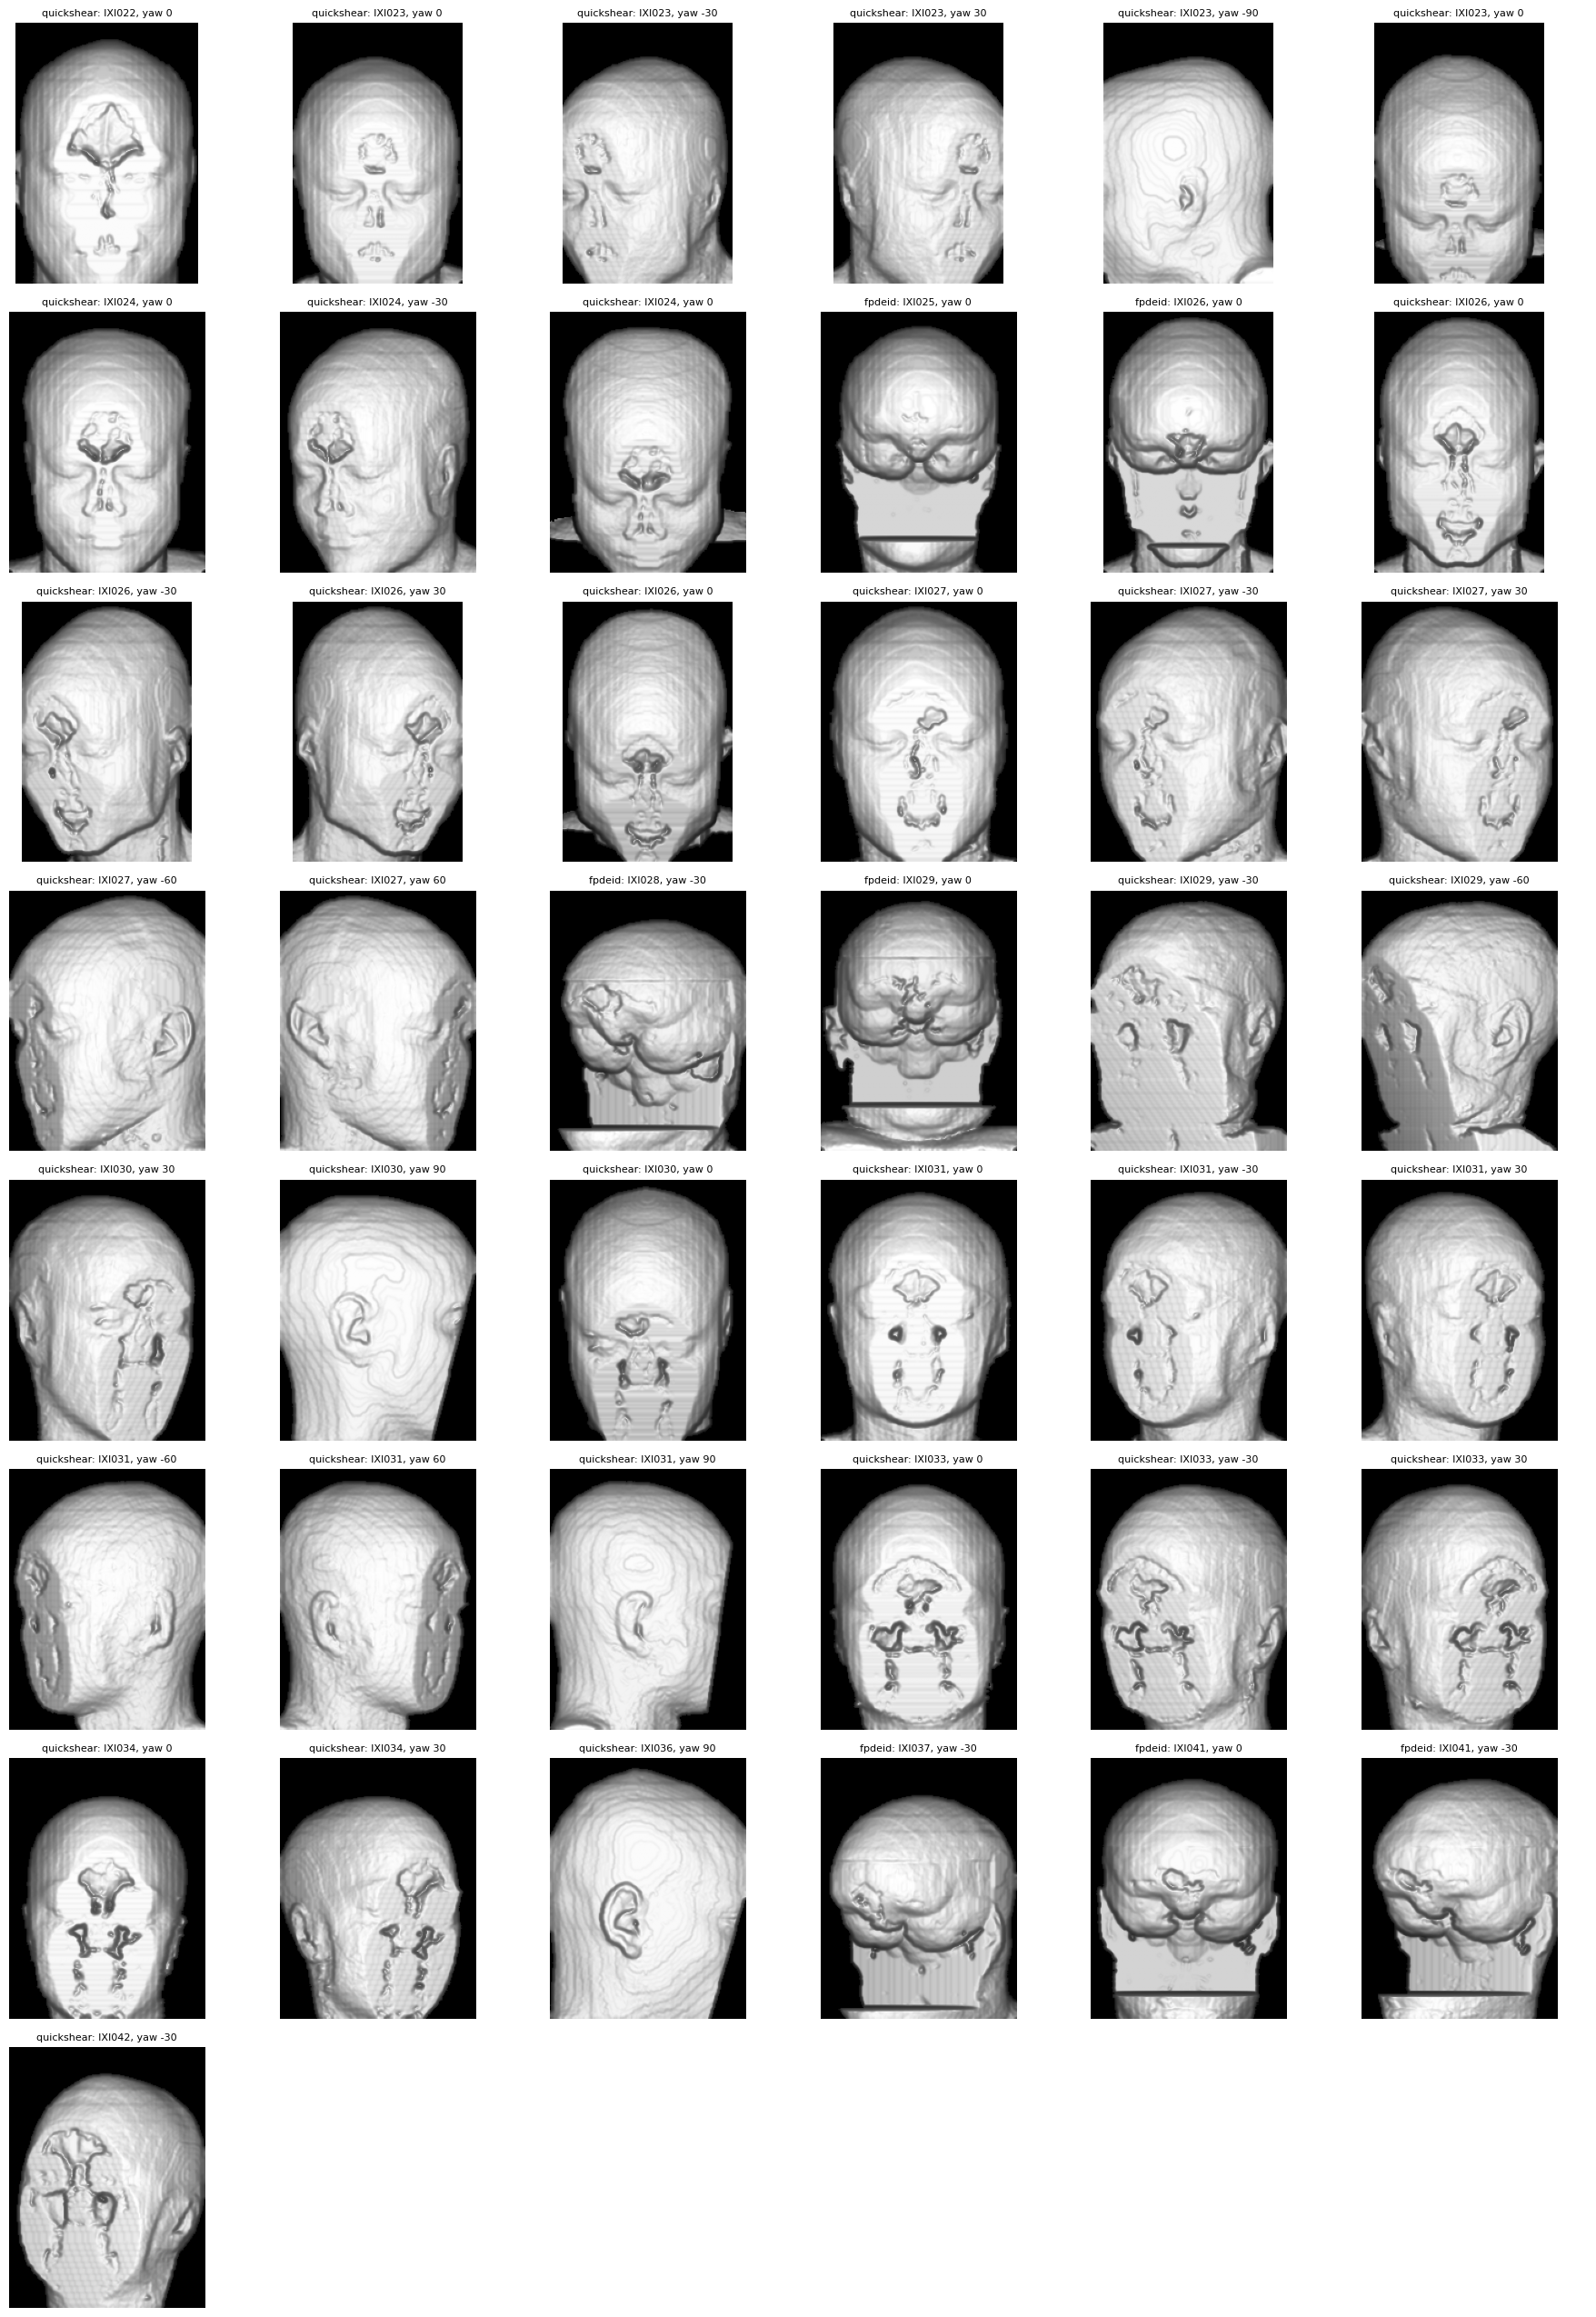

In [10]:
# every view of a FP-DeID or quickshear test scan where both detectors still find a "face", to check by eye
flagged = []
for _, row in problems.iterrows():
    if row["views with a face (both agree)"] == 0 or row["method"] == "box":
        continue
    item = loaded[os.path.join(paths.DATA, "ixi", "t1", row["scan"])]
    defaced, removed, seconds = run_method(item, row["method"], MARGIN, ABOVE, BELOW)
    head_iso = deface.isotropic(deface.head_mask(defaced), item["zooms"])
    for yaw, pitch in deface.VIEWS:
        picture = deface.render(head_iso, yaw, pitch)
        if detectors.detect(picture)["both"]:
            flagged.append((row["method"] + ": " + row["scan"][:6] + ", yaw " + str(yaw), picture))
print("views to check by eye:", len(flagged))
if len(flagged) > 0:
    columns = min(6, len(flagged))
    lines = int(np.ceil(len(flagged) / columns))
    fig, axes = plt.subplots(lines, columns, figsize=(3 * columns, 3.2 * lines), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (title, picture) in zip(axes.ravel(), flagged):
        ax.imshow(picture, cmap="gray")
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(phase_results, "remaining_detections.png"), dpi=90)
    plt.show()

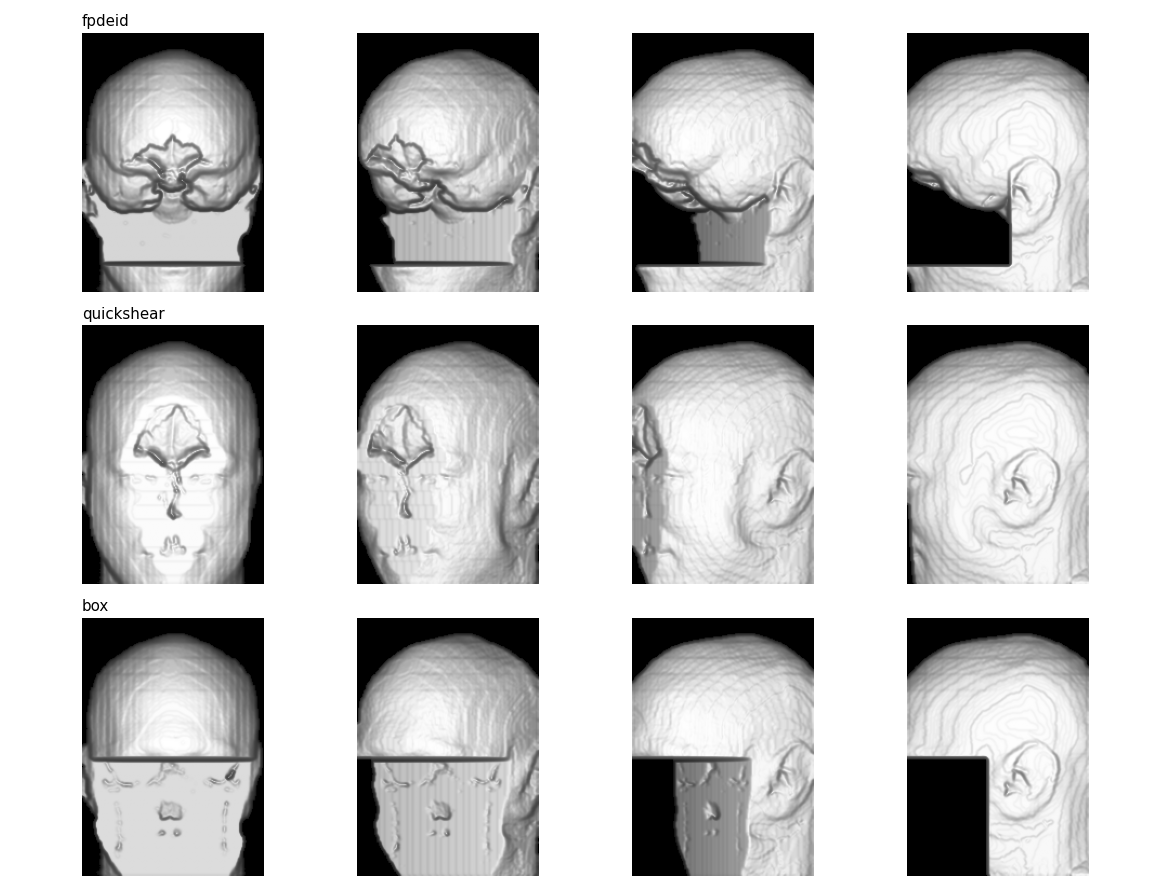

In [11]:
# renders of one test scan after each method (the original face is not shown)
item = loaded[test_scans[0]]
rows = dict(saved_examples)
fig, axes = plt.subplots(len(rows), 4, figsize=(13, 3.3 * len(rows)))
for r, (name, volume) in enumerate(rows.items()):
    head_iso = deface.isotropic(deface.head_mask(volume), item["zooms"])
    for c, (yaw, pitch) in enumerate([(0, 0), (-30, 0), (-60, 0), (-90, 0)]):
        axes[r, c].imshow(deface.render(head_iso, yaw, pitch), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(name, loc="left")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "renders.png"), dpi=90)
plt.show()

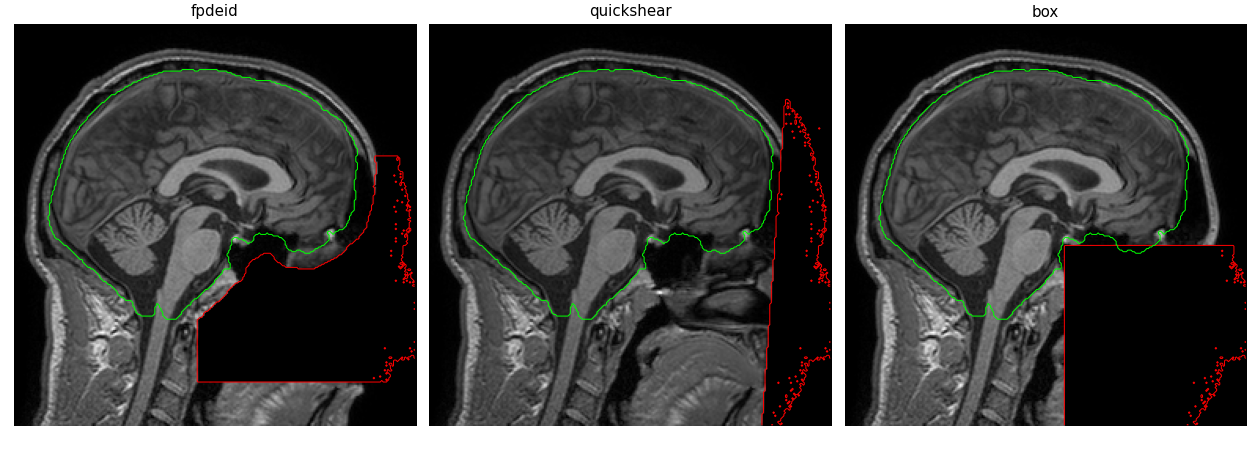

In [12]:
# middle sagittal slice after each method (red outline = removed region, green = brain)
middle = item["volume"].shape[0] // 2
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, method in zip(axes, ["fpdeid", "quickshear", "box"]):
    defaced = saved_examples[method]
    removed = item["volume"][middle] != defaced[middle]
    ax.imshow(np.rot90(defaced[middle]), cmap="gray")
    ax.contour(np.rot90(removed), levels=[0.5], colors="red", linewidths=0.8)
    ax.contour(np.rot90(item["brain"][middle]), levels=[0.5], colors="lime", linewidths=0.8)
    ax.set_title(method)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(phase_results, "sagittal.png"), dpi=90)
plt.show()

## 5. The same on DICOM: a head MRI written as a DICOM series, defaced series by series
MIDI-B has no head scans, so one IXI volume is written as a DICOM series (one file per slice) and cleaned with
`deface.deface_dicom_series`. The result must equal the defaced volume, and only face pixels may change.

In [13]:
dicom_folder = os.path.join(paths.DATA, "tmp", "dicom_head")
shutil.rmtree(dicom_folder, ignore_errors=True)
item = loaded[test_scans[0]]
input_files = deface.write_series(item["volume"], item["affine"], os.path.join(dicom_folder, "input"))
output_files = [path.replace("input", "output") for path in input_files]
os.makedirs(os.path.join(dicom_folder, "output"), exist_ok=True)
print("head series detected:", deface.is_head_series(pydicom.dcmread(input_files[0], stop_before_pixels=True)))
start = time.time()
dicom_result = deface.deface_dicom_series(input_files, output_files, MARGIN, ABOVE, BELOW)
dicom_seconds = time.time() - start
print(dicom_result, "| seconds:", round(dicom_seconds, 1))

pairs_in, volume_in, affine_in, orientation_in = deface.series_ras(input_files)
pairs_out, volume_out, affine_out, orientation_out = deface.series_ras(output_files)
zooms_in = np.sqrt((affine_in[:3, :3] ** 2).sum(axis=0))
direct, removed_direct = deface.deface_fpdeid(volume_in, deface.brain_mask(volume_in, affine_in), zooms_in,
                                              MARGIN, ABOVE, BELOW)
same_voxels = float((direct == volume_out).mean())
print("voxels where DICOM and volume defacing agree:", round(100 * same_voxels, 4), "%",
      "| voxels that differ:", int((direct != volume_out).sum()))
headers_same = 0
for a, b in zip(input_files, output_files):
    ds_a = pydicom.dcmread(a, stop_before_pixels=True)
    ds_b = pydicom.dcmread(b, stop_before_pixels=True)
    if all(ds_a[tag].value == ds_b[tag].value for tag in ds_a.keys()):
        headers_same = headers_same + 1
print("headers unchanged:", headers_same, "of", len(input_files))
shutil.rmtree(dicom_folder, ignore_errors=True)

head series detected: True


{'slices': 256, 'slices changed': 144, 'removed voxels': 1941533, 'brain voxels': 1776920} | seconds: 28.2


voxels where DICOM and volume defacing agree: 100.0 % | voxels that differ: 0


headers unchanged: 256 of 256


## 6. Phase 7 summary vs. pass criteria

In [14]:
fp = summary.loc["fpdeid"]
criteria = pd.DataFrame([
    ["faces before defacing (test, 160 views, both detectors agree)", "≈ 100% of front views", str(faces_before_test) +
     " views; front views: " + str(int(before[before["scan"].isin(test_names) & before["view"].isin(
         ["yaw 0, pitch 0", "yaw -30, pitch 0", "yaw 30, pitch 0", "yaw 0, pitch -20"])]["both"].sum())) + " / 80"],
    ["faces after FP-DeID defacing (160 views, both detectors agree)", "0", int(fp["views with a face (of 160)"])],
    ["faces after quickshear / box (160 views)", "reported", str(int(summary.loc["quickshear", "views with a face (of 160)"]))
     + " / " + str(int(summary.loc["box", "views with a face (of 160)"]))],
    ["brain voxels changed (FP-DeID)", "0", int(fp["brain voxels changed"])],
    ["skull-strip Dice before vs after (FP-DeID)", "≥ 0.99", round(fp["skull-strip Dice"], 4)],
    ["tissue segmentation Dice (FP-DeID)", "≥ 0.99", round(fp["tissue Dice (mean of CSF, GM, WM)"], 4)],
    ["brain volume change (FP-DeID)", "< 0.5%", round(fp["|brain volume change| %"], 3)],
    ["removed tissue: FP-DeID / quickshear / box (ml)", "reported",
     str(round(fp["removed tissue ml"])) + " / " + str(round(summary.loc["quickshear", "removed tissue ml"])) + " / " +
     str(round(summary.loc["box", "removed tissue ml"]))],
    ["runtime per scan (SynthStrip + defacing)", "reported",
     str(round(float(np.mean(strip_seconds)) + fp["deface seconds (without SynthStrip)"], 1)) + " s"],
    ["DICOM series: same voxels as volume defacing", "100%", round(100 * same_voxels, 3)],
    ["DICOM series: headers unchanged", "100%", str(headers_same) + " / " + str(len(input_files))],
], columns=["check", "target", "result"])
criteria.to_csv(os.path.join(phase_results, "pass_criteria.csv"), index=False)
criteria

,check,target,result
0,"faces before defacing (test, 160 views, both d...",≈ 100% of front views,88 views; front views: 76 / 80
1,"faces after FP-DeID defacing (160 views, both ...",0,7
2,faces after quickshear / box (160 views),reported,36 / 11
3,brain voxels changed (FP-DeID),0,0
4,skull-strip Dice before vs after (FP-DeID),≥ 0.99,0.9941
5,tissue segmentation Dice (FP-DeID),≥ 0.99,0.9859
6,brain volume change (FP-DeID),< 0.5%,0.699
7,removed tissue: FP-DeID / quickshear / box (ml),reported,918 / 272 / 887
8,runtime per scan (SynthStrip + defacing),reported,30.2 s
9,DICOM series: same voxels as volume defacing,100%,100.0
